# `Matplotlib` 資料視覺化

`matplotlib` 幾乎是標準 Python 畫圖套件了! 在有 `matplotlib` 之前, Python 要畫圖不那麼方便, 和 Python 很多套件一樣, 有許多方案, 但各家有不同的優缺點, 也沒有一套是大家都在用的。

而 `matplotlib` 仿 Matlab 式的畫圖方式, 讓很多人很快入手、並且功能相當完整。原作者是 John D. Hunter, 和很多 Python 的套件作者一樣, 他有博士學位。非常令人遺憾的是他在 2012 年因大腸直腸癌治療併發症過逝, 過逝時才 44 歲!


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1 畫個函數

前面說過 `plt.plot` 的基本用法是

    plt.plot(X,Y)

其中 X, Y 是分別是點 x 座標, y 座標形的的 list 或 array。

### 【重點】標準函數畫法

函數畫圖其實就是描點法, 而且再次用到陣列導向計算的概念。

我們先牛刀小試, 畫個 $\sin$ 的圖。

$$f(x) = \sin(x)$$

先來設個 x 的範圍, 就 -10 到 10, 給 100 個點。

In [4]:
x=np.linspace(-10,10,100)

y 自然是 $\sin(x)$。

In [5]:
y=np.sin(x)

畫圖!

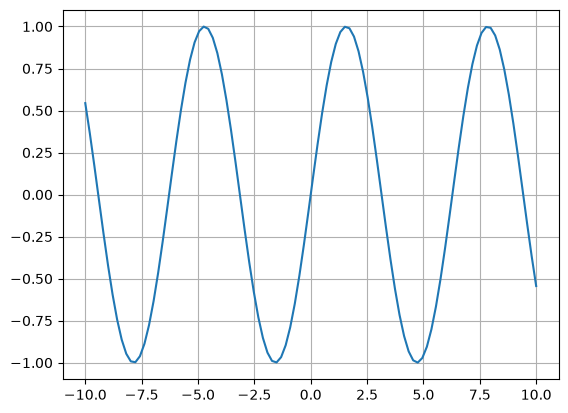

In [6]:
plt.plot(x,y);plt.grid();plt.show()

### 【練習】函數畫圖

這次我們來畫:

$$f(x) = \frac{\sin(5x)}{1+x^2}$$

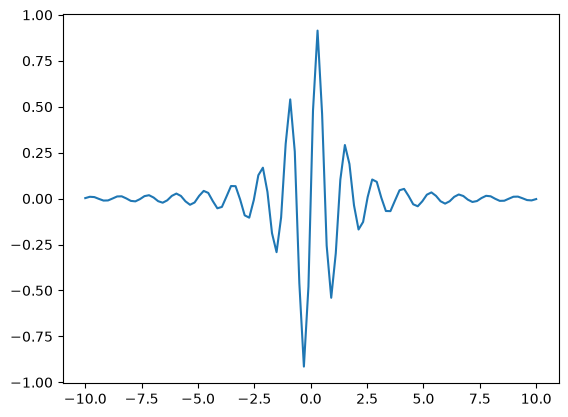

In [7]:
plt.plot(x,np.sin(5*x)/(1+x**2));plt.show()

## 2 快速改變風格

雖然 `matplotlib` 在很辛苦的調校之後也是可以畫美美的圖, 不過它比較是「讓我們快速看到結果」的套件。所以它有些快速基本修飾功能。

### 【技巧】快速改變顏色

![快取色彩](images/color.png)

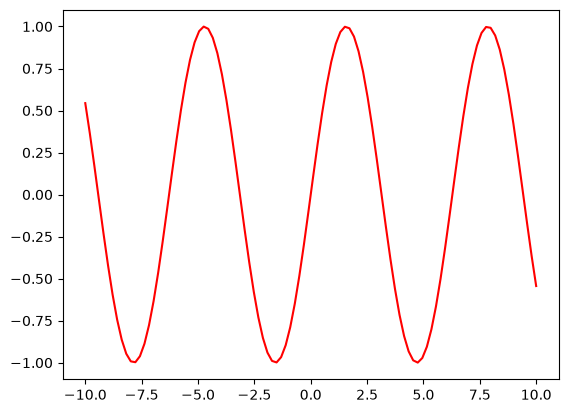

In [8]:
plt.plot(x,y,"r");plt.show()

### 【技巧】快速改變線條風格

快速改變線條風格, 還可和顏色混用。

| 參數 | 說明 |
|---|---|
| `--` | dash |
| `-.` | 點 + dash |
| `:` | 點點 |
| `o` | 大點點 |
| `^` | 三角 |
| `s` | 方塊 |

ValueError: 'delta' is not a valid format string (unrecognized character 'e')

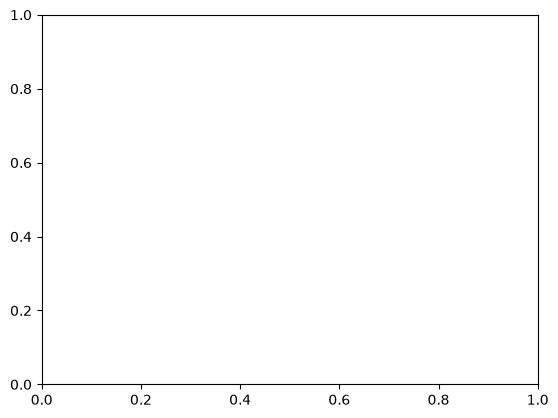

In [28]:
plt.plot(x,y,"delta");plt.show()

## 3 基本的修飾

| 參數 | 說明 |
|---|---|
| `alpha` | 透明度 |
| `color` (`c`)| 顏色 |
| `linestyle` (`ls`) | 線條風格 |
| `linewidth` (`lw`) | 線寬 |

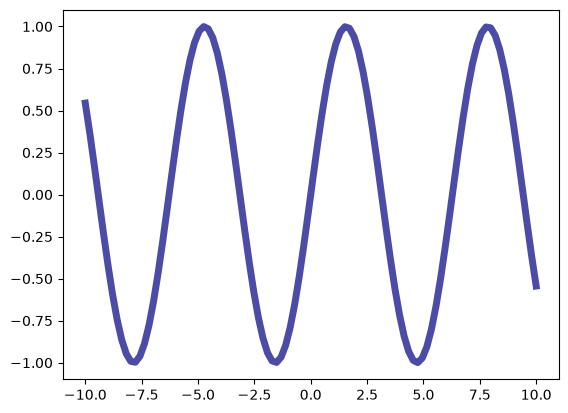

In [18]:
plt.plot(x,y,color="navy",linewidth=5,alpha=.7);plt.show()

## 4 如果畫個參數式圖形

其實參數式圖形基本上也是一堆 x, y 的座標, 只是 x(t), y(t) 都是 t 的函數, 我們可以想成 t 是時間。

假設我們的

$$ -2\pi \leq t \leq 2\pi$$

要畫個半徑是 r 的圓, x(t), y(t) 就是這樣:

* $x(t) = r\cos(t)$
* $y(t) = r\sin(t)$

我們來試試事情是不是如我們想的這樣...

In [19]:
t=np.linspace(-2*np.pi,2*np.pi,400)
r=2

In [20]:
xx=r*np.cos(t);yy=r*np.sin(t)

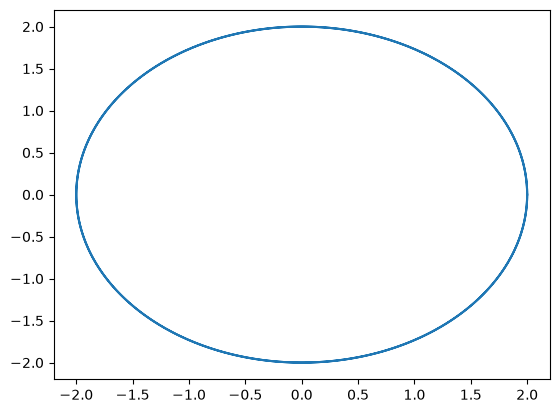

In [21]:
plt.plot(xx,yy);plt.show()

真的成功了... 等等, `matplotlib` 怎麼畫成橢圓呢? 我們來調整一下。

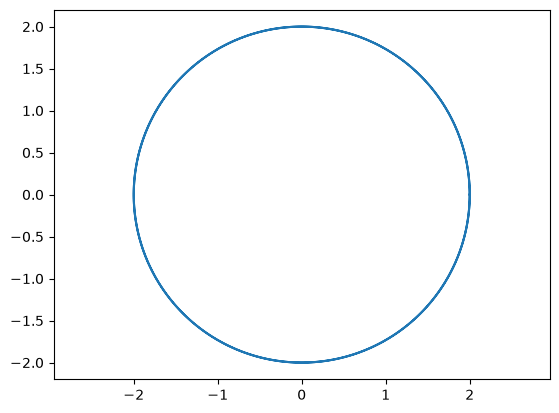

In [22]:
plt.plot(xx,yy);plt.axis("equal");plt.show()

再來我們可以想一下, 如果 r 不是故定的呢? 也就是它會變長變短, 是不是會畫出很多特別的圖呢? 其實很多特別的曲線不過就是找個試合的 r(t), 我們來隨意試試看。

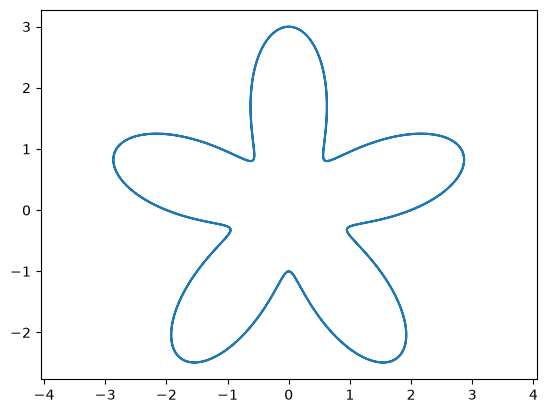

In [23]:
r=2+np.sin(5*t)
plt.plot(r*np.cos(t),r*np.sin(t));plt.axis("equal");plt.show()

是不是很有意思呢? 你也可以自己試試不同的變化。

## 5 `subplot` 畫多個圖

我們每次畫圖的時候, `matplotlib` 就弄 1 個 figure 畫圖區出來, 裡面可以有很多子圖, 在 figure 裡叫 axes。目前我們都只有 1 個 figure 內含 1 張圖, 所以都不用設, 現在我想畫 4 張圖時。我們就要先想好「陣式」。

比如說 2x2 這樣排列的 4 張圖。

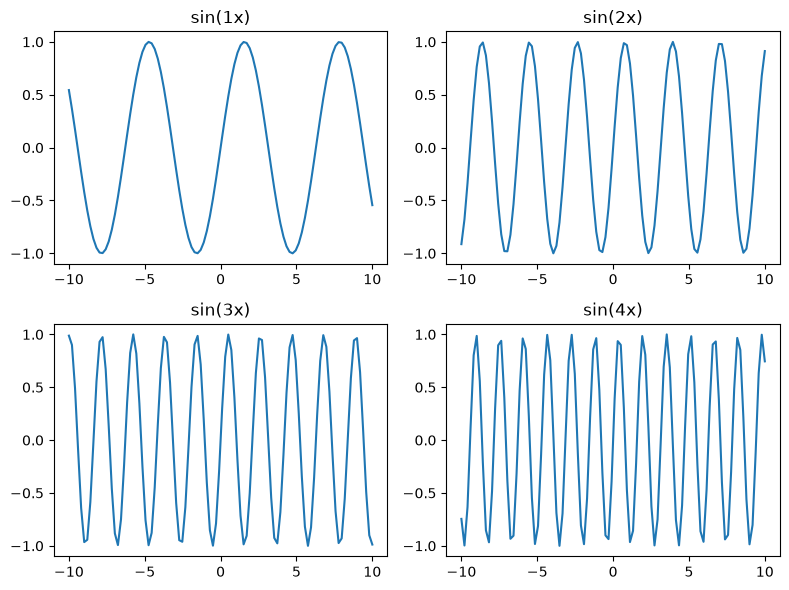

In [24]:
fig,axs=plt.subplots(2,2,figsize=(8,6))
for i,ax in enumerate(axs.flat,1):ax.plot(x,np.sin(i*x));ax.set_title(f"sin({i}x)")
plt.tight_layout();plt.show()

## 6 進階色彩*

#### 顏色表示法 1

    c = 'r' 

可以用 blue (b), green (g), red (r), cyan (c), magenta (m), yellow (y), black (k), white (w)


#### 顏色表示法 2

用一個 0 到 1 的數字表灰階, 越大越白。

    c = '0.6'
    
#### 顏色表示法 3

網頁常用的標準 16 進位 RGB 表示法。

    c = '#00a676'
    
我們怎知哪裡可選顏色呢? 可以用之前彥良介紹的 [Coolors.co](https://coolors.co) 等。
    
#### 顏色表示法 4

用 0-1 的數字表 RGB 也可以。

    c=(0.7, 0.4, 1)

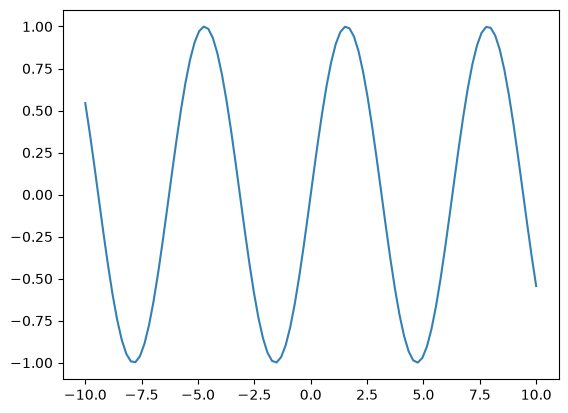

In [29]:
plt.plot(x,y,color=(.2,.5,.7));plt.show()

## 7 Marker*

所謂 'marker' 就是原來的點, 我們特別標示出來, 為了不要讓圖形太複雜, 我們新換個點比較少的例子。

In [30]:
xx=np.arange(1,11);yy=xx**2

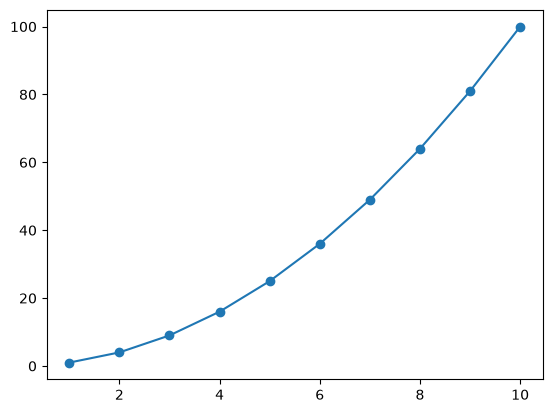

In [31]:
plt.plot(xx,yy,"o-");plt.show()

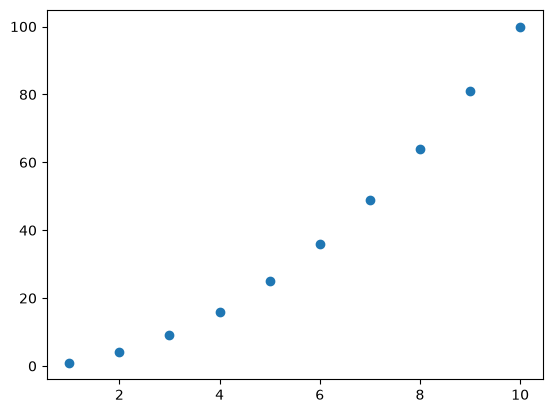

In [32]:
plt.scatter(xx,yy);plt.show()

#### marker 可以設的參數

| 參數 | 說明 |
|---|---|
| `marker` | marker 的風格 |
| `markeredgecolor` (`mec`) | 邊線顏色 |
| `markeredgewidth` (`mew`) | 邊線寬度 |
| `markerfacecolor` (`mfc`) | marker 的顏色 |
| `markerfacecoloralt` (`mfcalt`) | marker 替換色 |
| `markersize` (`ms`) | marker 大小 |
| `markevery` | 隔多少畫一個 marker |

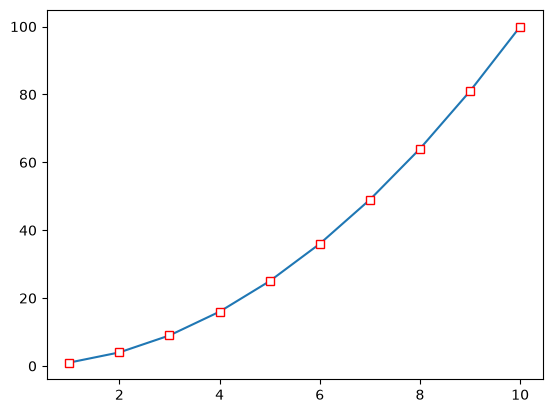

In [33]:
plt.plot(xx,yy,marker="s",mec="red",mfc="white");plt.show()

比較奇特的參數是 `markevery`, 這是說我們每多少筆資料要畫一個 marker。為了示範, 我們拿之前的例子來看看。

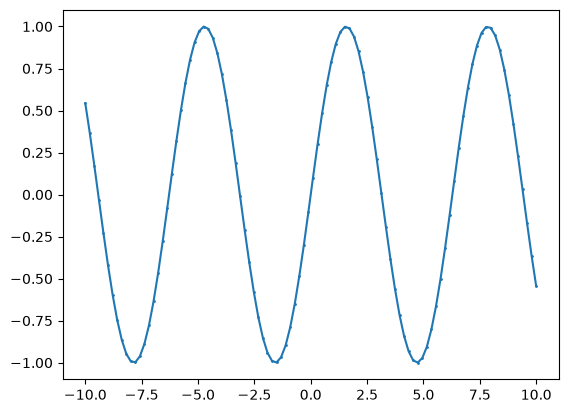

In [36]:
plt.plot(x,y,marker="o",markersize=1);plt.show()

後面的完完全全連在一起了, 我們現在隔 10 個畫一個 marker 試試。

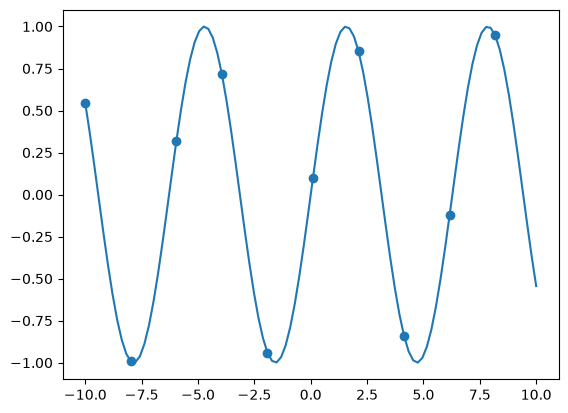

In [37]:
plt.plot(x,y,marker="o",markevery=10);plt.show()

## 8 bar 風*

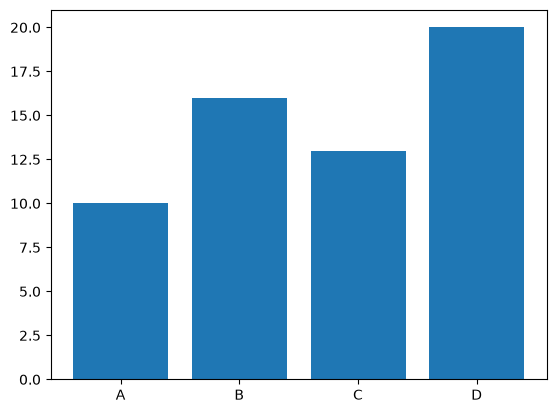

In [38]:
labels=["A","B","C","D"];a=np.array([10,16,13,20]);b=np.array([7,12,8,15]);idx=np.arange(4)
plt.bar(idx,a);plt.xticks(idx,labels);plt.show()

移一點點。

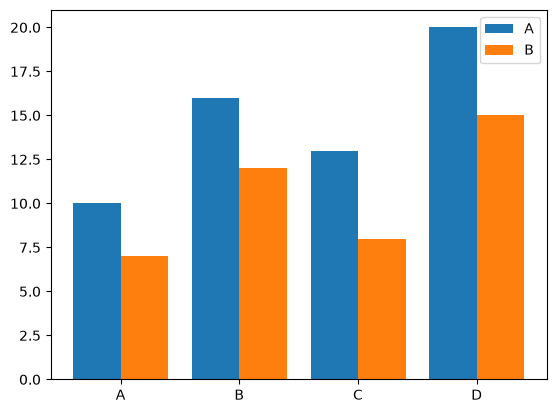

In [39]:
plt.bar(idx-.2,a,width=.4,label="A");plt.bar(idx+.2,b,width=.4,label="B");plt.xticks(idx,labels);plt.legend();plt.show()

#### 雙色的長條圖

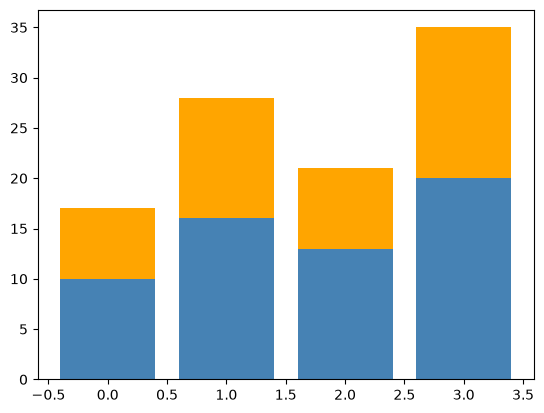

In [40]:
plt.bar(idx,a,color="steelblue");plt.bar(idx,b,bottom=a,color="orange");plt.show()

#### 疊加型的資料

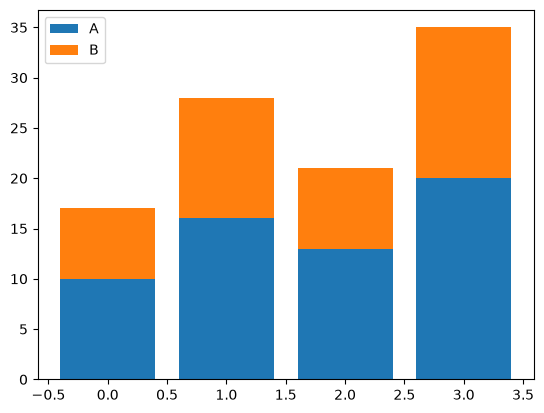

In [41]:
plt.bar(idx,a,label="A");plt.bar(idx,b,bottom=a,label="B");plt.legend();plt.show()

#### 橫放的長條圖

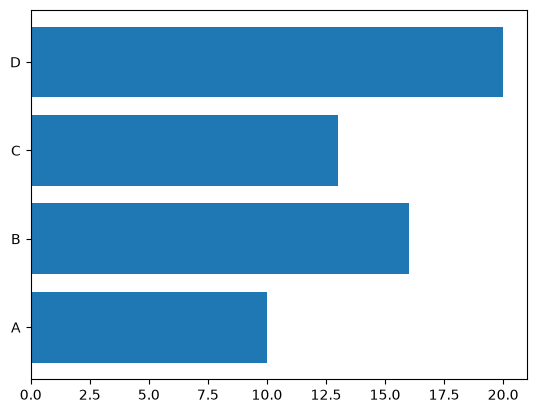

In [42]:
plt.barh(labels,a);plt.show()

#### 雙向的長條圖

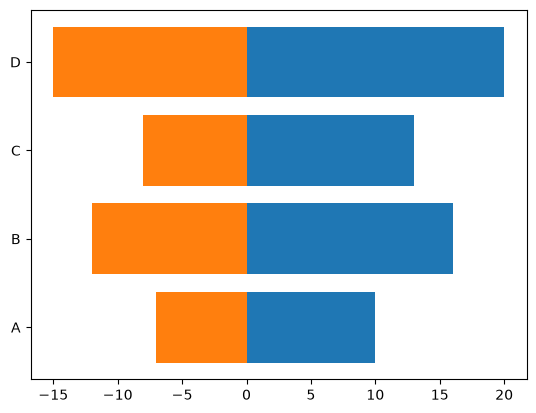

In [43]:
plt.barh(labels,a);plt.barh(labels,-b);plt.show()

## 9 畫圖區的設定*

#### 說明文字的標示

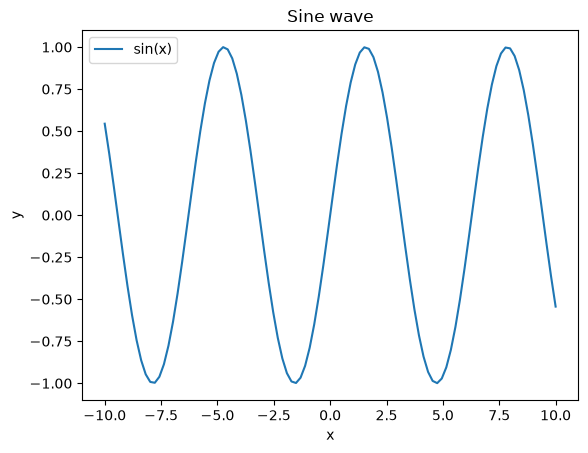

In [44]:
plt.plot(x,y,label="sin(x)");plt.xlabel("x");plt.ylabel("y");plt.title("Sine wave");plt.legend();plt.show()

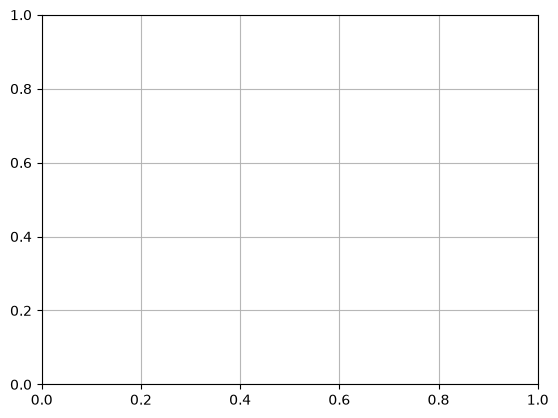

In [46]:
plt.grid(alpha=.9);plt.show()

#### 邊界的設定

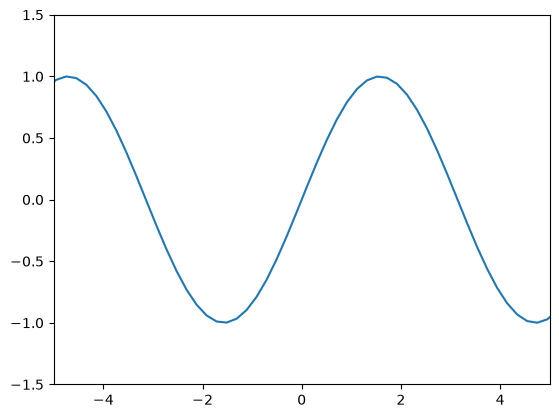

In [47]:
plt.plot(x,y);plt.xlim(-5,5);plt.ylim(-1.5,1.5);plt.show()

#### xticks

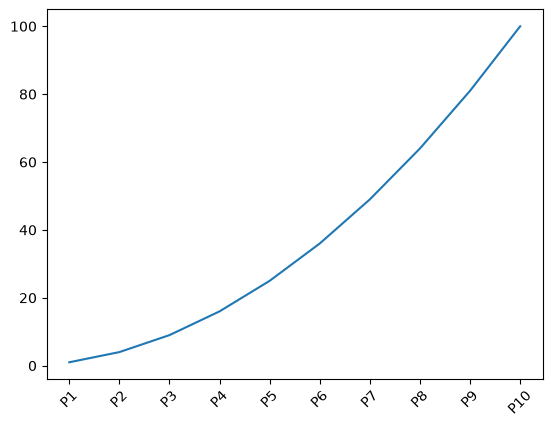

In [48]:
plt.plot(xx,yy);plt.xticks(xx,labels=[f"P{i}" for i in xx],rotation=45);plt.show()

# [練習]自己生成測試數據，X軸xticks對應到y軸數值

例如: 1,2,3,4,5 對應X軸 '甲','乙'...

#### 圖例 legend

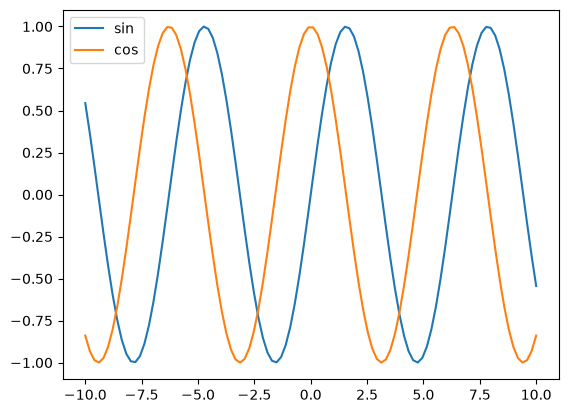

In [49]:
plt.plot(x,np.sin(x),label="sin");plt.plot(x,np.cos(x),label="cos");plt.legend();plt.show()

可用 `loc` 去設圖例的位置, 依 1, 2, 3, ... 表示。

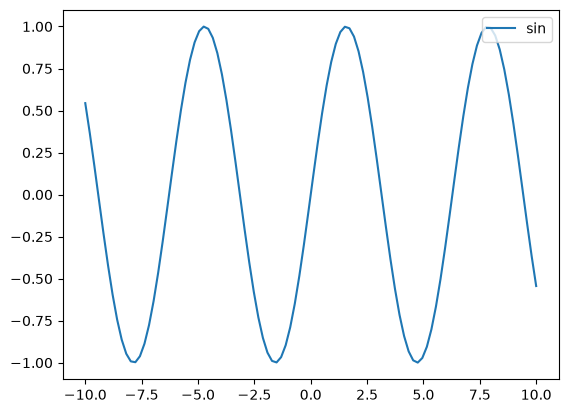

In [50]:
plt.plot(x,y,label="sin");plt.legend(loc="upper right");plt.show()

## 10 取得現在工作中 axes*

我們有時要設 axes 的背景啦等等的資訊。這時就要取得現在工作中的 axes。這一般有兩種方式, 第一種是設 `subplot` 時可以取得:

    fig, ax = plt.subplot()
    
另一種是用 `gca` 函數:

    ax = plt.gca()

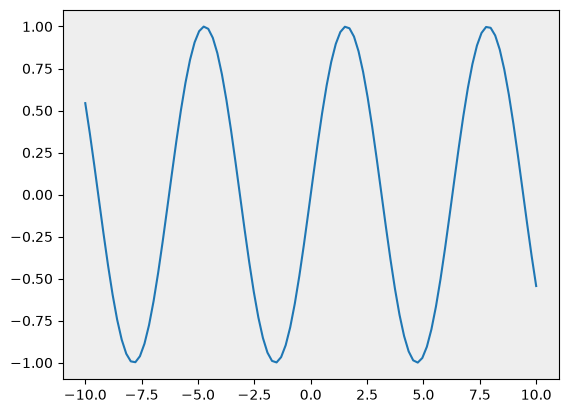

In [51]:
fig,ax=plt.subplots();ax.plot(x,y);ax.set_facecolor("#eeeeee");plt.show()

#### 移動 x, y 座標軸

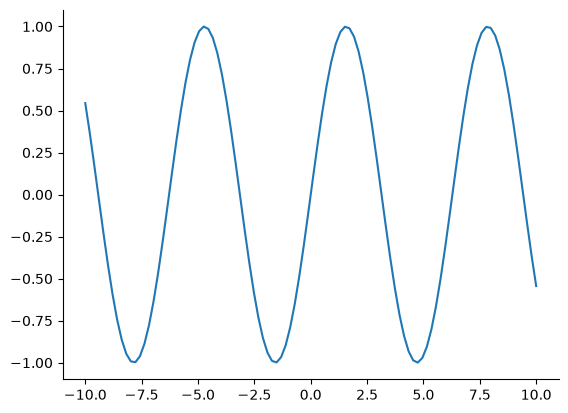

In [52]:
fig,ax=plt.subplots();ax.plot(x,y);ax.spines["top"].set_visible(False);ax.spines["right"].set_visible(False);plt.show()

## 11 耍寶可愛的 `xkcd`*

findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd S

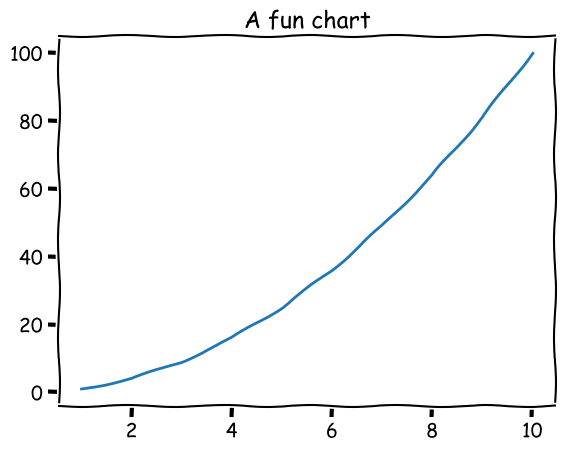

In [53]:
with plt.xkcd():
 plt.plot(xx,yy);plt.title("A fun chart");plt.show()

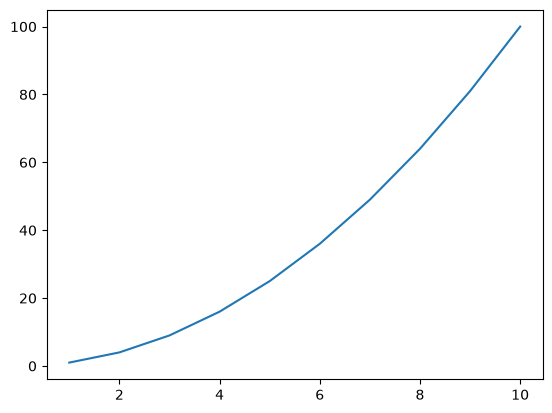

In [54]:
plt.plot(xx,yy);plt.show()

## 12 `seaborn` 大救星

雖然 `matplotlib` 幾乎什麼都可以調, 但有些簡單的調整卻要花費很多時間。於是有了許多可以協助 `matplotlib` 變美、變方便的套件出現。最近有個很有名的叫 `seaborn`, 儼然有另一個標準套件的態式。

最重要的是 `seaborn` 和我們未來要介紹的 `pandas` 配合得非常好, 雖然熊貓和海生的聽來就沒什麼關係...

我們先來個標準 (又來標準縮寫) 讀入 `seaborn` 的方法。

In [55]:
sns.set_theme(style="whitegrid")

然後像平常畫個圖。

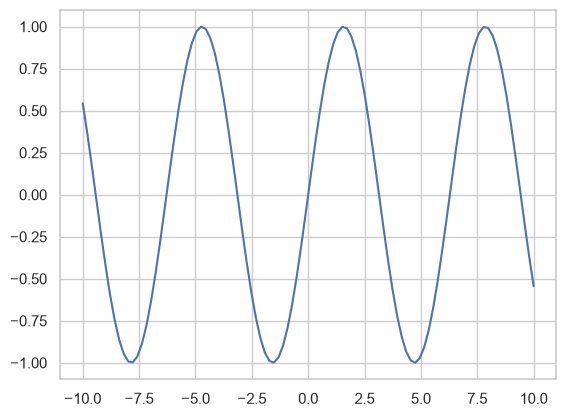

In [56]:
plt.plot(x,y);plt.show()

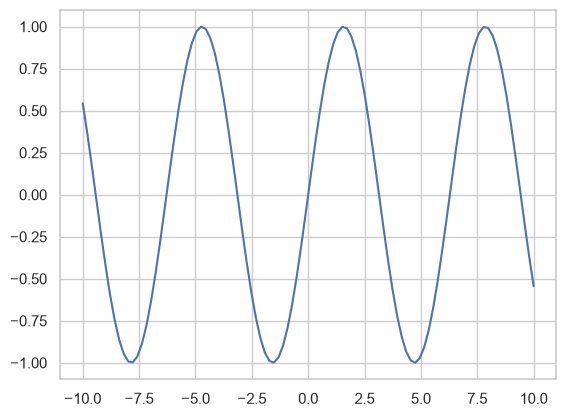

In [57]:
sns.lineplot(x=x,y=y);plt.show()

傑克, 這真是太神奇了!

總之, 你根本就直接用原來 `matplotlib` 的指令, 馬上 `seaborn` 就會幫你美化。當然我們還是可以做更多的控制, 詳情請參考

[seaborn 的網站](https://seaborn.github.io/)

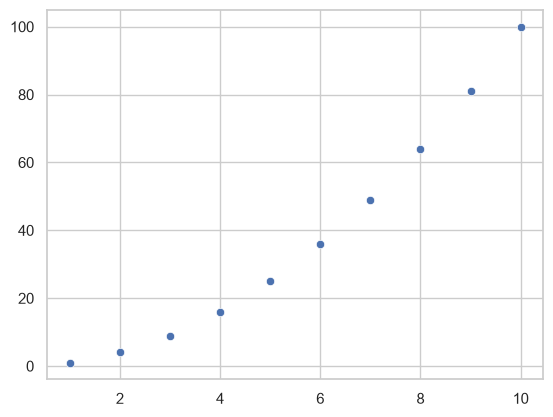

In [58]:
sns.scatterplot(x=xx,y=yy);plt.show()

In [59]:
sns.reset_defaults()